# Task 5 — Capstone: redesign one chart for the human visual system
**CLO1.** Data: `gapminder.csv` (142 countries × 12 years = 1,704 rows).

**The one question a reader should be able to answer:** *How did life expectancy change in each country between 1952 and 2007, and is
there any country that stands out?*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# find the data folder whether the notebook sits in assignments/ or one level up
DATA = next(p for p in (Path("data"), Path("assignments/data"), Path("week2/assignments/data")) if p.exists())

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
})
GREY, RED, BLUE = "#bbbbbb", "#ee6677", "#4477aa"

from IPython.display import Markdown, display
gm = pd.read_csv(DATA / "gapminder.csv")
print(gm.shape, "| countries:", gm.country.nunique(), "| years:", gm.year.nunique(), "| missing:", int(gm.isna().sum().sum()))
low = gm.loc[gm.lifeExp.idxmin()]
print(f"Lowest life expectancy anywhere in the data: {low.country}, {low.year}, {low.lifeExp:.1f} years")
w = gm.pivot(index="country", columns="year", values="lifeExp")
fell = list(w.index[w[2007] < w[1952]])
print(f"Countries whose life expectancy was LOWER in 2007 than 1952: {len(fell)} -> {fell}")

(1704, 6) | countries: 142 | years: 12 | missing: 0
Lowest life expectancy anywhere in the data: Rwanda, 1992, 23.6 years
Countries whose life expectancy was LOWER in 2007 than 1952: 2 -> ['Swaziland', 'Zimbabwe']


## Step 1 — A genuinely bad chart
A spaghetti line chart: 142 lines, a different colour for each (cycling a rainbow-like map), no way to know which is which.

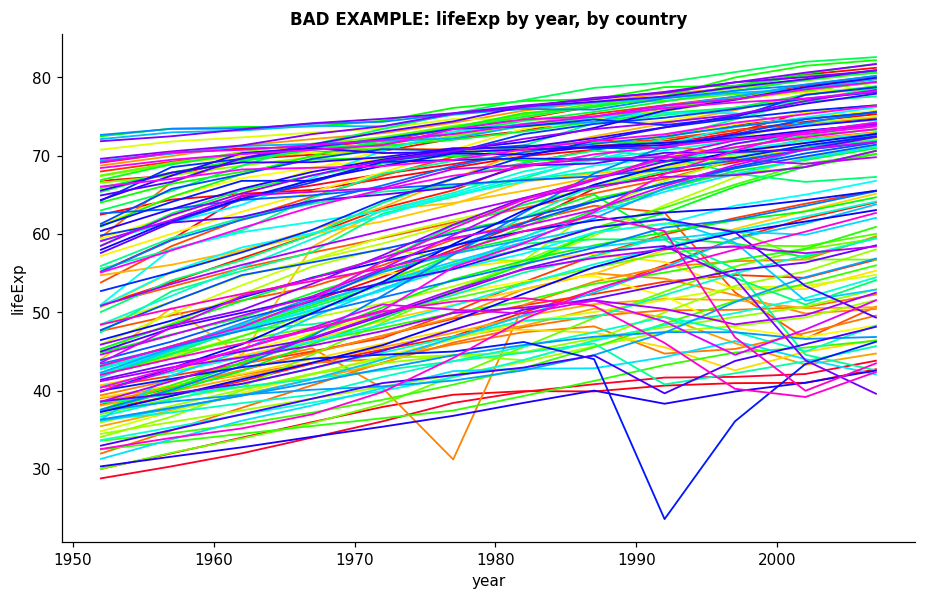

In [2]:
fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.cm.gist_rainbow
for i, (country, d) in enumerate(gm.groupby("country")):
    ax.plot(d.year, d.lifeExp, color=cmap(i / 142), lw=1.2)
ax.set_xlabel("year"); ax.set_ylabel("lifeExp")
ax.set_title("BAD EXAMPLE: lifeExp by year, by country")
fig.savefig("task5_bad_example.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 2 — Perception audit of the bad chart
| Row | Audit of the **BAD EXAMPLE** |
|---|---|
| **Preattentive** | Hue is in play on all 142 lines, but with that many hues none stands out, so colour does no useful work. Position (x = year, y = life expectancy) does the useful work, but it is buried under the tangle. |
| **Pop-out** | Nothing deliberate pops out. If anything, the eye is pulled to the densest crossing of lines or to the bottom-left outlier dip — and that is accidental. The title claims nothing. |
| **Gestalt** | Continuity makes each line trace a path, but at 142 lines the crossings are ambiguous: the eye cannot keep one line separate from its neighbours. Similarity is useless because neighbouring hues look alike. There is no grouping that corresponds to a question. |
| **Cognitive load** | *Intrinsic:* 142 time series. *Extraneous:* 142 colours that carry no meaning, the absence of any direct label, the axis names as title, default `lifeExp`/`year` labels. *Germane:* almost none; the reader cannot build a mental model. |
| **Channels** | Life expectancy → position (rank 1, appropriate). Year → position (rank 1, appropriate). Country → hue (colour is for categories, but with 142 categories it is far past what hue can encode; it only works for a handful). |
| **Working memory** | To say anything, the reader would need to hold the trajectory of an unlabelled coloured line across the chart: effectively an unbounded number of chunks (well over the 4 ± 1 limit). |

## Step 3 — Rebuild: one figure, one message
**Message:** the data hold one extreme point. Rwanda in 1992 is the lowest life expectancy of any country in any year.

Design decisions and the attribute they rely on:
* **One pop-out:** a single Rwanda line in strong colour (**preattentive hue + thicker width**: two cues for the same element, so colour is not the only carrier). Direct label on the line, so no legend.
* **Context in grey:** the other 141 countries, thin, semi-transparent.
* **Named Gestalt principle: Similarity.** The 141 identical grey lines are read as *one background group* because they look alike; Rwanda differs and so separates from them. (Continuity lets the eye follow each line, but similarity is the principle doing the grouping.)
* **Highest-ranking channel for the key variable:** life expectancy on **position** (common y scale), time on position (x).
* **No information by colour alone:** the pop-out is also thicker and labelled with text and a value.
* **`n` and exclusions declared** on the figure.

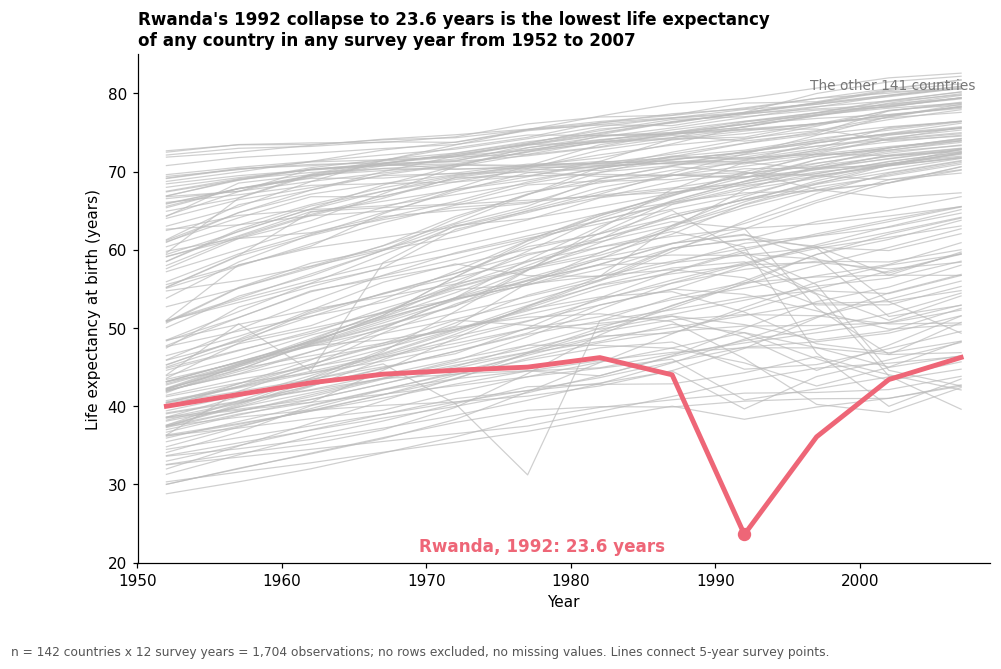

In [3]:
rw = gm[gm.country == "Rwanda"].sort_values("year")
rw_low = rw.loc[rw.lifeExp.idxmin()]

fig, ax = plt.subplots(figsize=(10, 6))
for country, d in gm.groupby("country"):
    if country != "Rwanda":
        ax.plot(d.year, d.lifeExp, color=GREY, lw=0.8, alpha=0.7, zorder=1)
ax.plot(rw.year, rw.lifeExp, color=RED, lw=3.2, zorder=3)
ax.scatter([rw_low.year], [rw_low.lifeExp], color=RED, s=60, zorder=4)
ax.annotate(f"Rwanda, {int(rw_low.year)}: {rw_low.lifeExp:.1f} years",
            xy=(rw_low.year, rw_low.lifeExp), xytext=(rw_low.year - 14, rw_low.lifeExp - 2.2),
            color=RED, fontsize=11, fontweight="bold", ha="center")
ax.text(2008, 80.5, "The other 141 countries", color="#777777", ha="right", fontsize=9)
ax.set_xlim(1950, 2009); ax.set_ylim(20, 85)
ax.set_xlabel("Year"); ax.set_ylabel("Life expectancy at birth (years)")
ax.set_title(f"Rwanda's {int(rw_low.year)} collapse to {rw_low.lifeExp:.1f} years is the lowest life expectancy\n"
             "of any country in any survey year from 1952 to 2007", loc="left")
fig.text(0.01, -0.03, "n = 142 countries x 12 survey years = 1,704 observations; no rows excluded, no missing values. Lines connect 5-year survey points.",
         fontsize=8, color="#555555")
fig.savefig("perception_redesign.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 4 — Audit of the redesign, before and after
| Row | **Before (BAD EXAMPLE)** | **After (redesign)** |
|---|---|---|
| **Preattentive** | 142 hues, none doing useful work; position carries the data under a tangle. | One hue contrast (red vs grey) plus one width difference on the single Rwanda line; position carries the data cleanly. |
| **Pop-out** | Nothing deliberate; accidental pull to dense line crossings. | Exactly one: the Rwanda line and its low point. It is the thing the title says. |
| **Gestalt** | Continuity creates ambiguous crossings; similarity does not help; nothing groups to answer a question. | **Similarity:** 141 identical grey lines read as one background group; Rwanda is the lone exception. Continuity still lets the eye follow it. |
| **Cognitive load** | Intrinsic: 142 series. Extraneous: 142 colours, no labels, axis-name title. Germane: ~none. | Intrinsic: 142 series (unchanged, cannot be removed; but greyed so the reader does not have to process them). Extraneous: removed colour, legend, box and gridlines. Germane: the annotated low point, the axis, the finding title. |
| **Channels** | life expectancy → position; year → position; country → hue (poor for 142 categories). | life expectancy → position; year → position; country → *not encoded* except Rwanda (labelled directly), so no weak channel is carrying anything. |
| **Working memory** | Effectively unbounded. | About 2 chunks: "all the grey lines" and "Rwanda". |

**Self-audit:** every chart uses `fig, ax`; exactly one pop-out; Gestalt principle named (similarity); key variable on position;
every element classified; ≤ ~4 chunks; no information by colour alone (colour + width + label); context grey, message coloured; `n` and exclusions on the figure; the title states a finding.

## Step 5 — Test it on a human
Show a person who has not seen the data **the redesign only** (not the bad chart) and ask them to say in one sentence what it
shows. Record their sentence **verbatim** below. I have deliberately left this blank: it has to come from a real person.

In [4]:
READER = "a classmate"                       # ✏️ first name or "a classmate"
READER_SENTENCE = ""                          # ✏️ paste their one sentence, word for word

if READER_SENTENCE:
    display(Markdown(f"**Reader ({READER}) said:** \u201c{READER_SENTENCE}\u201d"))
else:
    print("Not recorded yet - show perception_redesign.png to someone and type their sentence into READER_SENTENCE.")

Not recorded yet - show perception_redesign.png to someone and type their sentence into READER_SENTENCE.


> ✏️ **Compare it with my title.** Does their sentence match "Rwanda's 1992 collapse is the lowest point in the data"? If not, say
> which part of the design misled them and what you would change next. Likely candidates: they read the chart as "life expectancy
> rose everywhere" (the grey lines, which all slope up, are the larger visual mass); they did not notice the label; or they asked
> *why* the dip happened, which the chart does not explain.

## Step 6 — Export
`perception_redesign.png` was saved above with `dpi=300, bbox_inches="tight"`. Quick check of the file:

In [5]:
from PIL import Image
im = Image.open("perception_redesign.png")
print("size (px):", im.size, "| dpi metadata:", im.info.get("dpi"))

size (px): (2730, 1817) | dpi metadata: (299.9994, 299.9994)


## The question to answer: what does the redesign make *harder* to see?
Greying 141 countries hides **the main story of the original data: life expectancy rose in almost every country**. The most
visible fact in the grey lines (a broad upward drift) is now *context*, not message, and a reader looking only at the red line could
overweight a single tragedy relative to the global trend. It also makes it harder to compare **countries or continents** with each
other: there is no way to see whether Africa rose slower than Europe, or that Swaziland and Zimbabwe ended below their 1952
level (the red line is the only trajectory I label). And the chart shows *that* Rwanda dropped, not *why* (that low value is generally linked to the war and genocide of the early 1990s, which the figure does not say).
A different message, such as "140 of 142 countries gained life expectancy between 1952 and 2007", would trade those costs differently, and would need its own chart.